In [1]:
from torch.utils.data import DataLoader
from utils import IQDataset 
from model import IQDenoiser
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

In [3]:
device = "cuda"

dataset = IQDataset(r"D:/VAE_GAN_DM/latent_bits_F/bits_8/tran_encode_RF_DDPM")

loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

model = IQDenoiser().to(device)
model.load_state_dict(
    torch.load(
        r"D:/VAE_GAN_DM/save_model/RF_DDPM/iq_denoiser.pth",
        map_location=device
    )
)

<All keys matched successfully>

In [4]:
noisy, clean = next(iter(loader))

model.eval()

with torch.no_grad():

    pred = model(noisy[:1].to(device))

pred = pred.cpu().numpy()[0]

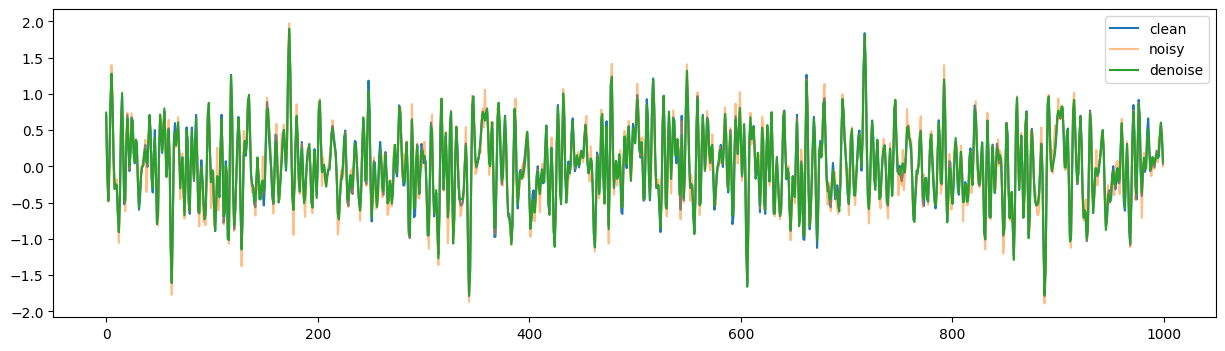

In [5]:
clean_np = clean[0].cpu().numpy()
noisy_np = noisy[0].cpu().numpy()

plt.figure(figsize=(15,4))

plt.plot(clean_np[0][:1000], label="clean")
plt.plot(noisy_np[0][:1000], alpha=0.5, label="noisy")
plt.plot(pred[0][:1000], label="denoise")

plt.legend()
plt.show()

In [6]:
mse_noisy = ((noisy_np - clean_np) ** 2).mean()
mse_pred  = ((pred - clean_np) ** 2).mean()

print("MSE noisy-clean:", mse_noisy)
print("MSE pred-clean :", mse_pred)
print("improvement:", mse_noisy / mse_pred)

MSE noisy-clean: 0.022886064
MSE pred-clean : 0.0047521573
improvement: 4.8159313
